# Comment note-t-on un film ? Exploitation de la base de données MovieLens 32M

## Introduction et problématique

# I - MovieLens 32M : téléchargement et aperçu des données

In [1]:
from donnees import telecharger, extraire
import os
import zipfile

import requests
import pandas as pd

URL = "https://files.grouplens.org/datasets/movielens/ml-32m.zip"
NOM_ZIP = "ml-32m.zip"
DOSSIER = "data"

In [2]:
telecharger(URL, NOM_ZIP)
extraire(NOM_ZIP, DOSSIER)

Le ZIP existe déjà, pas de nouveau téléchargement.
Contenu du ZIP : ['ml-32m/', 'ml-32m/tags.csv', 'ml-32m/links.csv', 'ml-32m/README.txt', 'ml-32m/checksums.txt', 'ml-32m/ratings.csv', 'ml-32m/movies.csv']


In [3]:
chemin = os.path.join(DOSSIER, "ml-32m")

movies = pd.read_csv(os.path.join(chemin, "movies.csv"))
tags = pd.read_csv(os.path.join(chemin, "tags.csv"))
links = pd.read_csv(os.path.join(chemin, "links.csv"))
ratings = pd.read_csv(os.path.join(chemin, "ratings.csv"))

In [ ]:
# Pour un téléchargement en local

import os

import pandas as pd

DOSSIER_CSV = "ml-32m"


movies = pd.read_csv(os.path.join(DOSSIER_CSV, "movies.csv"))
tags = pd.read_csv(os.path.join(DOSSIER_CSV, "tags.csv"))
links = pd.read_csv(os.path.join(DOSSIER_CSV, "links.csv"))
ratings = pd.read_csv(os.path.join(DOSSIER_CSV, "ratings.csv"))

display(movies.head())
display(ratings.shape)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


(32000204, 4)

On affiche le premier dataframe, qui comporte une clé d'identification des films (movieId), le titre ainsi que leur année, et le genre associé. 
La base de données comporte 87585 films.

In [4]:
print(movies.shape)
movies.head()

(87585, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


On affiche aussi les notes de ces films, qui vont être notre base de donnée principale. Le fichier est particulièrement volumineux (32 millions de notes). L'userId permet de voir quel utilisateur a mis quelle note, ce qui sera utile. 

In [8]:
print(ratings.shape)
ratings.head()

(32000204, 4)


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


La base de données donne aussi accès à des tags, c'est-à-dire des mots que les utilisateurs ont associé aux films. Nous choisissons de ne pas les étudier dans le cadre de ce projet.

In [6]:
print(tags.shape)
tags.head()

(2000072, 4)


,userId,movieId,tag,timestamp
0,22,26479,Kevin Kline,1583038886
1,22,79592,misogyny,1581476297
2,22,247150,acrophobia,1622483469
3,34,2174,music,1249808064
4,34,2174,weird,1249808102


Ce dataframe permet de faire des jointures avec des bases de données extérieures, en donnant la clé correspondante pour les films dans cette base et dans les bases IMDB et TMDB.

In [7]:
print(links.shape)
links.head()

(87585, 3)


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


## Création de dataframes utilisables pour l'analyse

On peut d'abord séparer l'année et le titre du film dans le dataframe movies.

In [9]:
movies_with_date = movies.copy()

# 1. on récupère l'année (4 chiffres entre parenthèses, à la fin du titre)
movies_with_date["year"] = movies_with_date["title"].str.extract(r"\((\d{4})\)\s*$", expand=False)

# 2. on enlève l'année du titre
movies_with_date["title"] = movies_with_date["title"].str.replace(r"\s*\(\d{4}\)\s*$", "", regex=True)

# 3. on convertit l'année en nombre
movies_with_date["year"] = pd.to_numeric(movies_with_date["year"])

movies_with_date

,movieId,title,genres,year
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995.0
1,2,Jumanji,Adventure|Children|Fantasy,1995.0
2,3,Grumpier Old Men,Comedy|Romance,1995.0
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995.0
4,5,Father of the Bride Part II,Comedy,1995.0
...,...,...,...,...
87580,292731,The Monroy Affaire,Drama,2022.0
87581,292737,Shelter in Solitude,Comedy|Drama,2023.0
87582,292753,Orca,Drama,2023.0
87583,292755,The Angry Breed,Drama,1968.0


Certains films n'ont pas de date, 617 sur 80 000 : 

In [10]:
movies_with_date[movies_with_date["year"].isna()]

,movieId,title,genres,year
15038,79607,"Millions Game, The (Das Millionenspiel)",Action|Drama|Sci-Fi|Thriller,NaN
18796,98063,Mona and the Time of Burning Love (Mona ja pal...,Drama,NaN
25425,123619,Terrible Joe Moran,(no genres listed),NaN
26356,125571,The Court-Martial of Jackie Robinson,(no genres listed),NaN
26381,125632,In Our Garden,(no genres listed),NaN
...,...,...,...,...
86528,288927,Fortunes,Comedy,NaN
86634,289193,The Wonderful Story of Henry Sugar,Adventure|Children|Comedy,NaN
86833,289909,Rattler,(no genres listed),NaN
87074,290775,Being Romanian: A Family Journal,(no genres listed),NaN


On exclut les films sans années, et on vérifie qu'elles ont bien été exclues. On réindexe bien les lignes aussi, sinon il y a un écart de 617 entre le nombre de lignes et le plus grand index. On peut aussi transformer les flottants en entiers maintenant qu'il n'y a plus de Na dans la colonne year.

In [11]:
movies_with_date = movies_with_date.dropna(subset=["year"]).reset_index(drop=True)
movies_with_date["year"].isna().sum()
movies_with_date["year"] = movies_with_date["year"].astype(int)


In [11]:
movies_with_date

,movieId,title,genres,year
0,1,Toy Story,Adventure|Animation|Children|Comedy|Fantasy,1995
1,2,Jumanji,Adventure|Children|Fantasy,1995
2,3,Grumpier Old Men,Comedy|Romance,1995
3,4,Waiting to Exhale,Comedy|Drama|Romance,1995
4,5,Father of the Bride Part II,Comedy,1995
...,...,...,...,...
86963,292731,The Monroy Affaire,Drama,2022
86964,292737,Shelter in Solitude,Comedy|Drama,2023
86965,292753,Orca,Drama,2023
86966,292755,The Angry Breed,Drama,1968


On peut aussi faire une jointure des notes et des films pour avoir le nom du film à côté de sa note. 
On commence par rajouter une colonne qui convertit le timestamp en heure lisible. Dans MovieLens, timestamp est un nombre de secondes écoulées depuis le 1er janvier 1970 (temps Unix).

In [12]:
ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="s")
ratings.head()

,userId,movieId,rating,timestamp,date
0,1,17,4.0,944249077,1999-12-03 19:24:37
1,1,25,1.0,944250228,1999-12-03 19:43:48
2,1,29,2.0,943230976,1999-11-22 00:36:16
3,1,30,5.0,944249077,1999-12-03 19:24:37
4,1,32,5.0,943228858,1999-11-22 00:00:58


In [13]:
ratings_movies = pd.merge(ratings, movies_with_date, on='movieId', how='inner')

In [14]:
ratings_movies

,userId,movieId,rating,timestamp,date,title,genres,year
0,1,17,4.0,944249077,1999-12-03 19:24:37,Sense and Sensibility,Drama|Romance,1995
1,1,25,1.0,944250228,1999-12-03 19:43:48,Leaving Las Vegas,Drama|Romance,1995
2,1,29,2.0,943230976,1999-11-22 00:36:16,"City of Lost Children, The (Cité des enfants p...",Adventure|Drama|Fantasy|Mystery|Sci-Fi,1995
3,1,30,5.0,944249077,1999-12-03 19:24:37,Shanghai Triad (Yao a yao yao dao waipo qiao),Crime|Drama,1995
4,1,32,5.0,943228858,1999-11-22 00:00:58,Twelve Monkeys (a.k.a. 12 Monkeys),Mystery|Sci-Fi|Thriller,1995
...,...,...,...,...,...,...,...,...
31965033,200948,79702,4.5,1294412589,2011-01-07 15:03:09,Scott Pilgrim vs. the World,Action|Comedy|Fantasy|Musical|Romance,2010
31965034,200948,79796,1.0,1287216292,2010-10-16 08:04:52,Centurion,Action|Adventure|Drama|Thriller|War,2010
31965035,200948,80350,0.5,1294412671,2011-01-07 15:04:31,Vampires Suck,Comedy,2010
31965036,200948,80463,3.5,1350423800,2012-10-16 21:43:20,"Social Network, The",Drama,2010


# III - Première approche du dataset

On regarde d’abord les années de sortie et les genres des films, puis la répartition des notes. 

### Par date de sortie des films

In [16]:
display(movies_with_date["year"].describe())

count    86968.000000
mean      1995.354809
std         26.011029
min       1874.000000
25%       1981.000000
50%       2006.000000
75%       2015.000000
max       2023.000000
Name: year, dtype: float64

Cette sortie décrit les années de sortie dans le dataset "movies_with_year". Les films sont sortis en moyenne en 1995 mais la médiane est 2006 donc il y a majoritairement des films récents dans le dataset (moins de 20 ans). Le plus vieux film de la database est sorti en 1874 et le plus récent est sorti en 2023, la base de données ne va pas jusqu'à aujourd'hui mais s'arrête en 2023.

Réalisons maintenant un histogramme pour représenter ces dates de sortie de films. Le premier film est sorti en 1874 et le dernier en 2023, on réalise donc 2023-1874+1=150 bins pour que chaque trait représente une année. 

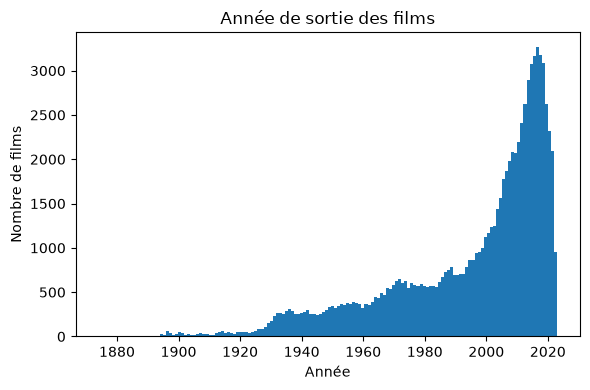

In [14]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))

movies_with_date["year"].plot(kind="hist", bins=150, ax=ax)
ax.set_title("Année de sortie des films")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()

On voit donc bien ici que la majorité des films du dataset sont sortis après 2000, il y a une surreprésentation des films qui sont sortis après la création de la base de données IMBd en 1990.

### Approche par notes des films

In [22]:
display(ratings_movies["rating"].describe())
display(ratings["rating"].value_counts().sort_index())

count    3.196504e+07
mean     3.540361e+00
std      1.058993e+00
min      5.000000e-01
25%      3.000000e+00
50%      3.500000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

rating
0.5     525132
1.0     946675
1.5     531063
2.0    2028622
2.5    1685386
3.0    6054990
3.5    4290105
4.0    8367654
4.5    2974000
5.0    4596577
Name: count, dtype: int64

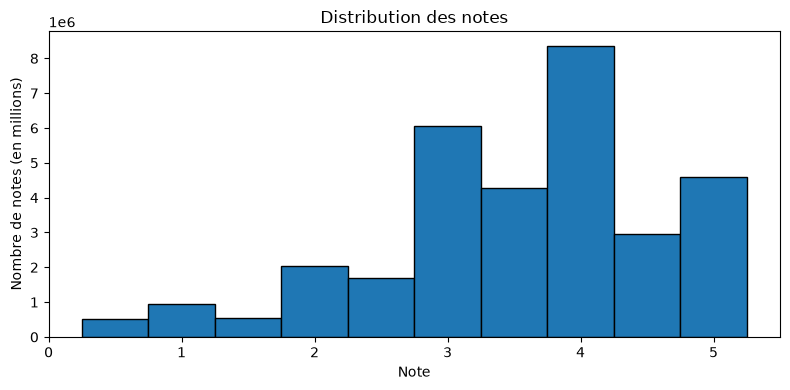

In [25]:
# Histogramme de toutes les notes
fig, ax = plt.subplots(figsize=(8, 4))
ratings_movies["rating"].plot(kind="hist", bins=[0.25 + 0.5 * i for i in range(11)], ax=ax, edgecolor="black")
ax.set_title("Distribution des notes")
ax.set_xlabel("Note")
ax.set_ylabel("Nombre de notes (en millions)")
plt.tight_layout()
plt.show()

Il y a 10 bins donc chaque rectangle est une note (0.5, 1, 1.5 ...). On peut donc voir les notes données par les utilisateurs. On observe que les notes entières sont systématiquements plus données que la note non entière supérieure et celle inférieure, on y voit peut-être là l'effet d'un biais psychologique qui fait préférer un chiffre entier à un non entier. 4 est la note la plus donnée, suivie de 3 puis 5. On voit donc que l'on donne aux films surtout des bonnes notes, et que l'extrême positif (5) est 9 fois plus fréquent que l'extrême négatif (0,5) (4,5 millions à 0,5 millions de notes).

On voudrait préciser l'analyse et la centrer sur les notes données aux films. On regarde donc les notes moyennes par film, et on en fait un histogramme.

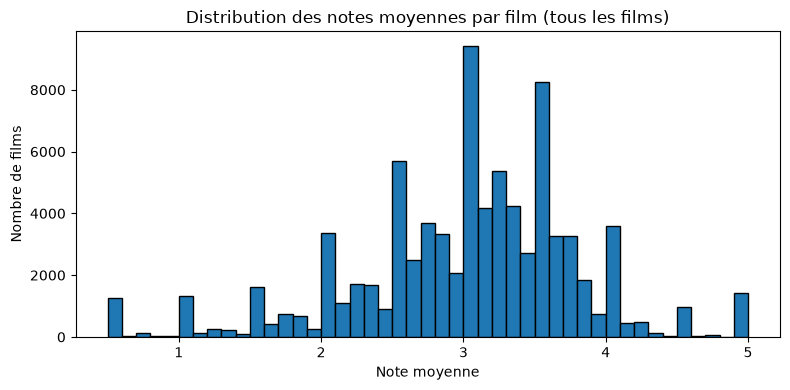

In [26]:
# Note moyenne et nombre de notes pour chaque film
notes_par_film = (
    ratings_movies
    .groupby("movieId")["rating"]
    .agg(note_moyenne="mean", nb_notes="count")
    .reset_index()
)

# 1. Histogramme des notes moyennes, tous les films
fig, ax = plt.subplots(figsize=(8, 4))
notes_par_film["note_moyenne"].plot(kind="hist", bins=45, ax=ax, edgecolor="black")
ax.set_title("Distribution des notes moyennes par film (tous les films)")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()


On remarque que cette représentation est assez éloignée d'une loi normale, on essaie de filtrer en ne gardant plus que les films qui ont un certain nombre de notes.

Films gardés : 15837


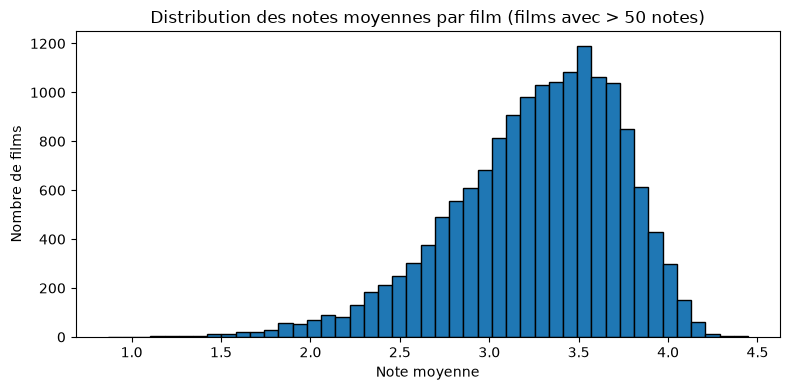

In [29]:
SEUIL = 50  # à modifier

# 2. Histogramme des notes moyennes, films avec plus de SEUIL notes
films_populaires = notes_par_film[notes_par_film["nb_notes"] > SEUIL]
print("Films gardés :", len(films_populaires))

fig, ax = plt.subplots(figsize=(8, 4))
films_populaires["note_moyenne"].plot(kind="hist", bins=45, ax=ax, edgecolor="black")
ax.set_title(f"Distribution des notes moyennes par film (films avec > {SEUIL} notes)")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()

Cette représentation se rapproche beaucoup d'une loi normale, de moyenne 3,5 environ.
La plupart des films sont bien notés, une moyenne en 3,5 à peu près, qui est supérieure à (5-0,5)/2 = 2,25 qui est la moyenne possible. Pourquoi est-ce qu'on note mieux que la moyenne, pourquoi les notes ne suivent pas une loi normale de moyenne 2,25 ?
Les notes plus basses sont rares, notamment parce qu'on ne regarde pas des films aléatoires, mais des films que l'on a envie de regarder, donc ils ont plus de chances de nous plaire (on peut toutefois être déçu bien sûr, cela n'empêche pas de mettre des mauvaises notes mais rend celles ci moins probables).

### Approche par genres des films

Intéressons nous désormais au genre des films. Créons un nouveau dataframe, qui duplique chaque ligne en autant de lignes que le film a de genres, pour rendre compte des différents genres des films.

In [30]:
# Une ligne par note et par genre
ratings_genres = ratings_movies.assign(genre=ratings_movies["genres"].str.split("|")).explode("genre")
display(ratings_genres[["userId", "movieId", "title", "rating", "genres", "genre"]].head(10))


KeyboardInterrupt: 

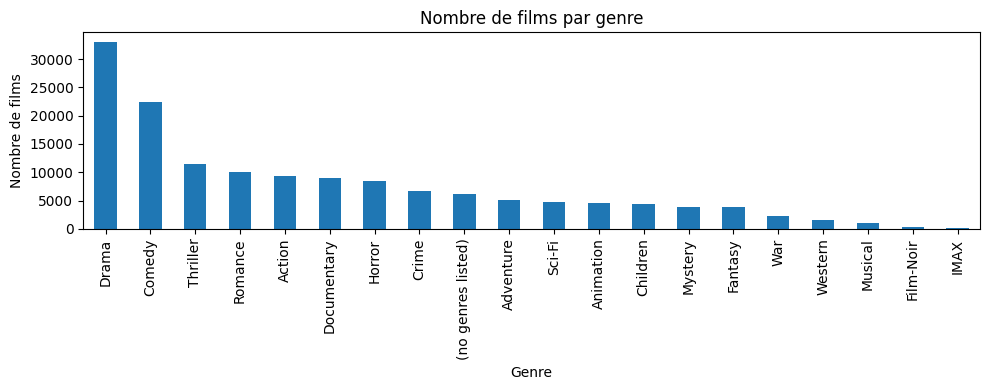

In [21]:
# Nombre de films par genre (chaque film compte dans tous ses genres)
films_par_genre = (
    ratings_genres
    .groupby("genre")["movieId"]
    .nunique()
    .sort_values(ascending=False)
)
films_par_genre.head()

# Graphique : nombre de films par genre
fig, ax = plt.subplots(figsize=(10, 4))
films_par_genre.plot(kind="bar", ax=ax)
ax.set_title("Nombre de films par genre")
ax.set_xlabel("Genre")
ax.set_ylabel("Nombre de films")
plt.tight_layout()
plt.show()


Certains genres sont surreprésentés, même si le classement dans un genre est partiellement arbitraire. Drama et comedy sont surreprésentés car on peut classifier la majorité des films dans une de ces catégories. Certaines films n'ont pas de catégorie (no genres listed), ou ont une catégorie qui a peu de sens (IMAX, qui signifie probablement spectaculaire, même si ce nom représente une technique plutôt qu'un genre cinématographique).

Représentons à présent les notes en fonction des genres.

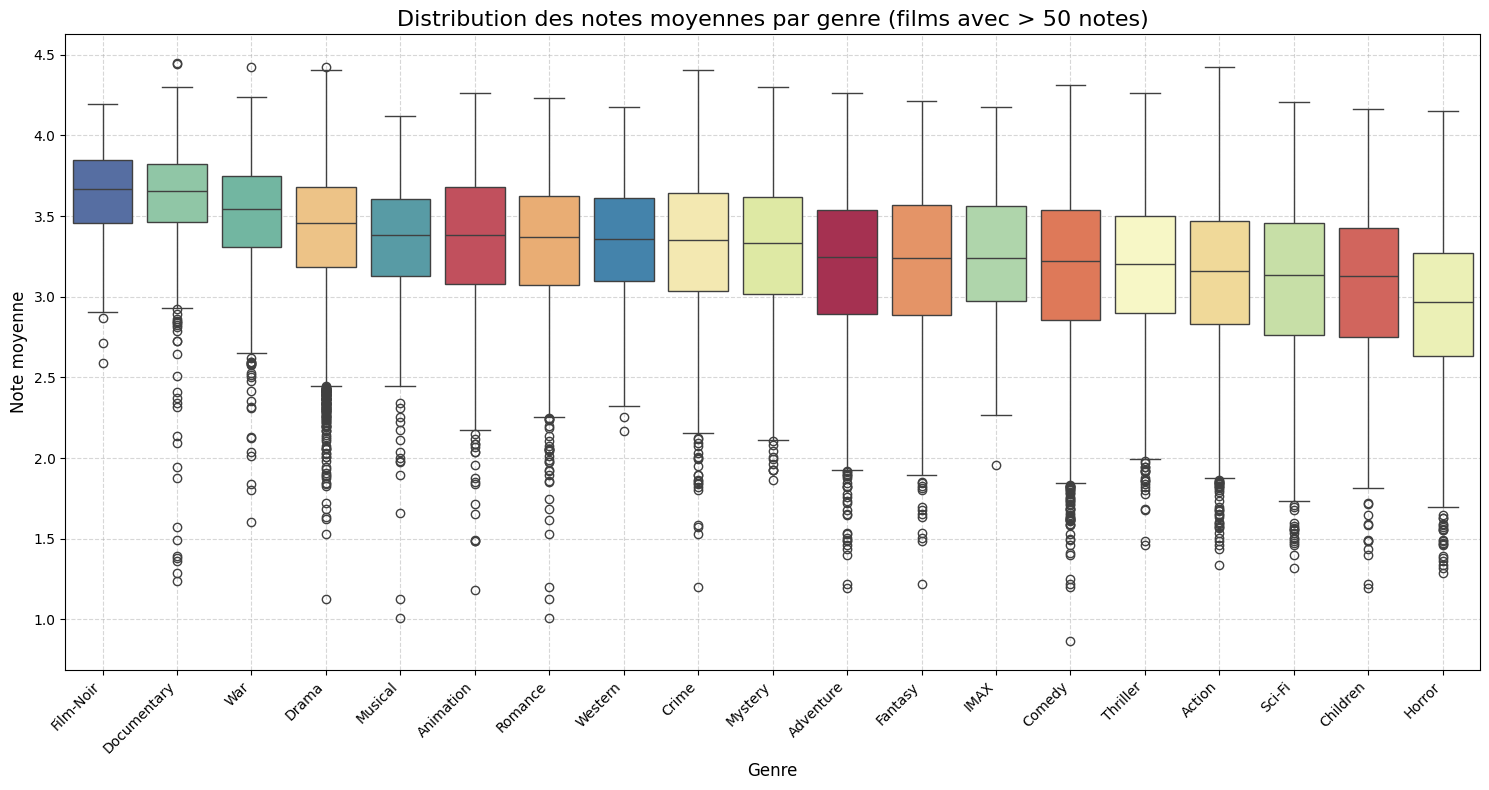

In [22]:
import seaborn as sns

SEUIL = 50  # à faire varier en fonction du nombre de notes chargées (plutôt 1000 si possible)

# 1. Note moyenne et nombre de notes par film
notes_par_film = (
    ratings_movies
    .groupby("movieId")["rating"]
    .agg(note_moyenne="mean", nb_notes="count")
    .reset_index()
)

# 2. Garder les films populaires et récupérer leurs genres
films_populaires = notes_par_film[notes_par_film["nb_notes"] > SEUIL]
films_populaires = films_populaires.merge(movies[["movieId", "genres"]], on="movieId")

# 3. Une ligne par genre pour chaque film
films_populaires["genre"] = films_populaires["genres"].str.split("|")
genres_df = films_populaires.explode("genre")
genres_df = genres_df[genres_df["genre"] != "(no genres listed)"]

# 4. Ordre des genres selon la médiane des notes moyennes
ordre = (
    genres_df
    .groupby("genre")["note_moyenne"]
    .median()
    .sort_values(ascending=False)
    .index
)

# 5. Boxplot
plt.figure(figsize=(15, 8))
sns.boxplot(
    data=genres_df,
    x="genre",
    y="note_moyenne",
    order=ordre,
    hue="genre",
    palette="Spectral",
    legend=False,
)
plt.title(f"Distribution des notes moyennes par genre (films avec > {SEUIL} notes)", fontsize=16)
plt.xlabel("Genre", fontsize=12)
plt.ylabel("Note moyenne", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

On enlève certains films qui sont très peu notés qui induisent beaucoup de variance. On voit donc qu'il y a une forte différence de notation en fonction du genre. Le genre "film noir" est le mieux noté, avec une note moyenne de 4 (probablement moins significative cependant parce qu'on a vu auparavant que le film noir était le genre le moins représenté), alors que le genre d'horreur est le moins bien noté à 3,3 en moyenne, avec une forte variance.

### Approche par utilisateurs



In [23]:
print("Nombre d'utilisateurs :", ratings_movies["userId"].nunique())

Nombre d'utilisateurs : 200948


dans la database ils ont tous au minimum 20 notes, donc pas besoin de filtre là dessus

Il y a X utilisateurs différents. 

In [24]:
# Statistiques par utilisateur
stats_users = (
    ratings_movies
    .groupby("userId")["rating"]
    .agg(note_moyenne="mean", variance="var", nb_notes="count")
    .reset_index()
)
display(stats_users.head())
stats_users.describe()

,userId,note_moyenne,variance,nb_notes
0,1,3.531915,2.365046,141
1,2,4.269231,1.259427,52
2,3,3.588435,1.029797,147
3,4,2.629630,1.088319,27
4,5,3.272727,0.829545,33


,userId,note_moyenne,variance,nb_notes
count,200948.000000,200948.000000,200948.000000,200948.000000
mean,100474.500000,3.704384,0.910827,159.071193
std,58008.835284,0.486605,0.541026,281.501897
min,1.000000,0.500000,0.000000,18.000000
25%,50237.750000,3.415326,0.539147,36.000000
50%,100474.500000,3.725000,0.800000,73.000000
75%,150711.250000,4.025000,1.157143,167.000000
max,200948.000000,5.000000,5.328947,33229.000000


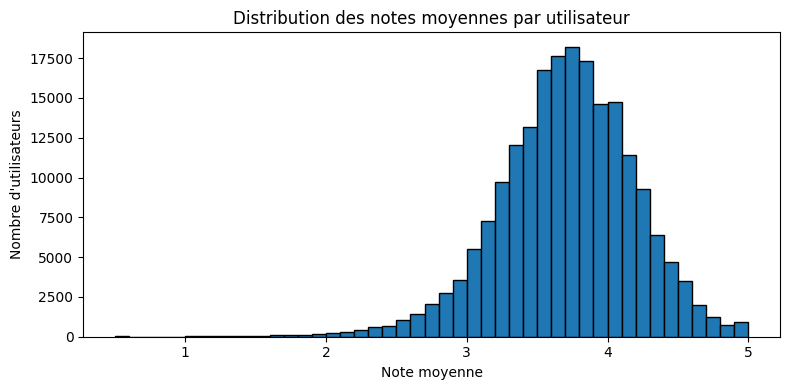

In [25]:
# Histogramme des notes moyennes par utilisateur
fig, ax = plt.subplots(figsize=(8, 4))
stats_users["note_moyenne"].plot(kind="hist", bins=45, ax=ax, edgecolor="black")
ax.set_title("Distribution des notes moyennes par utilisateur")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Nombre d'utilisateurs")
plt.tight_layout()
plt.show()

In [26]:
stats_users["note_moyenne"].describe()

count    200948.000000
mean          3.704384
std           0.486605
min           0.500000
25%           3.415326
50%           3.725000
75%           4.025000
max           5.000000
Name: note_moyenne, dtype: float64

La répartition des notes moyennes par utilisateur suit environ une loi normale de moyenne 3,7. La plupart des utilisateurs donnent des bonnes notes. 25% des utilisateurs donnent des notes supérieures à 4 en moyenne sont donc généreux.  

PAS OUBLIER DE DETAILLER PLUS LES ANALYSES

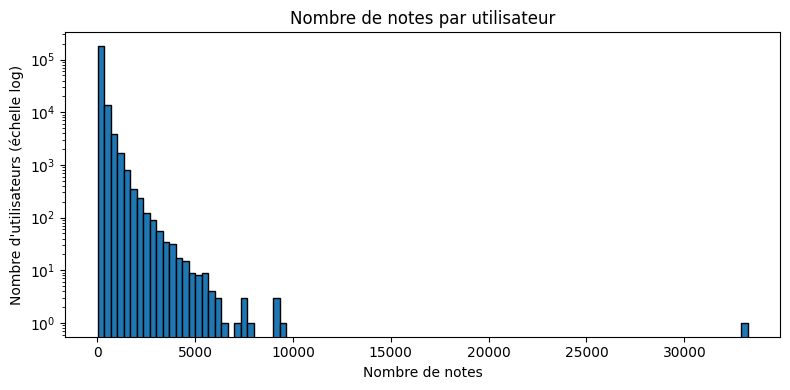

count    200948.000000
mean        159.071193
std         281.501897
min          18.000000
25%          36.000000
50%          73.000000
75%         167.000000
max       33229.000000
Name: nb_notes, dtype: float64

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
stats_users["nb_notes"].plot(kind="hist", bins=100, ax=ax, edgecolor="black")
ax.set_yscale("log")  # quelques gros utilisateurs écrasent le reste
ax.set_title("Nombre de notes par utilisateur")
ax.set_xlabel("Nombre de notes")
ax.set_ylabel("Nombre d'utilisateurs (échelle log)")
plt.tight_layout()
plt.show()

stats_users["nb_notes"].describe()

Les profils des utilisateurs sont donc très différents, certains sont très actifs.

Essayer de définir des profils d'utilisateurs en fonction de leur note moyenne et de leur variance.

Utilisateurs gardés : 195506


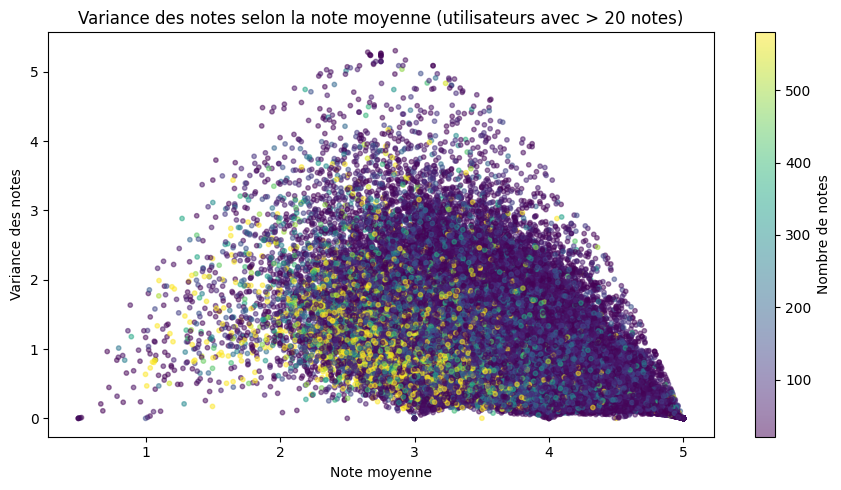

In [28]:
users_actifs = stats_users[stats_users["nb_notes"] > 20]
print("Utilisateurs gardés :", len(users_actifs))

fig, ax = plt.subplots(figsize=(9, 5))
points = ax.scatter(
    users_actifs["note_moyenne"],
    users_actifs["variance"],
    c=users_actifs["nb_notes"],
    cmap="viridis",
    vmax=users_actifs["nb_notes"].quantile(0.95),  # évite qu'un seul gros utilisateur écrase les couleurs
    alpha=0.5,
    s=10,
)
fig.colorbar(points, ax=ax, label="Nombre de notes")
ax.set_title("Variance des notes selon la note moyenne (utilisateurs avec > 20 notes)")
ax.set_xlabel("Note moyenne")
ax.set_ylabel("Variance des notes")
plt.tight_layout()
plt.show()

,note_moyenne,nb_notes
anciennete,,
0,3.562482,27065120
1,3.437095,1321523
2,3.418746,855652
3,3.430314,625816
4,3.435322,449851
5,3.410186,332710
6,3.402215,242987
7,3.398269,183494
8,3.401733,137543


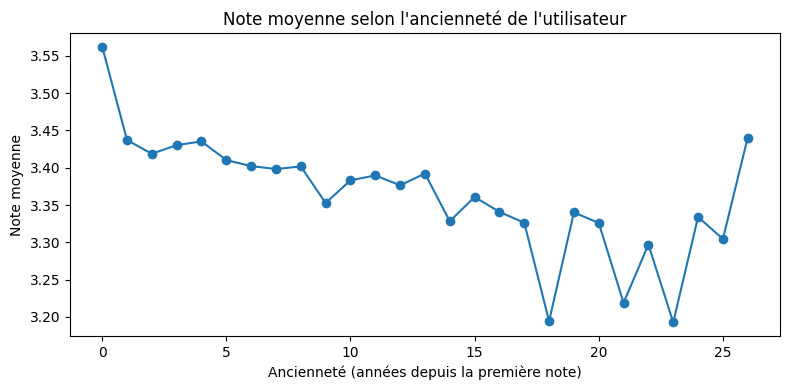

In [29]:
def ajouter_anciennete(df):
    """Ajoute l'ancienneté (en années entières) de chaque note par rapport à la première note de l'utilisateur."""
    df = df.copy()
    premiere_date = df.groupby("userId")["date"].transform("min")
    df["anciennete"] = (df["date"] - premiere_date).dt.days // 365
    return df


# On ne garde que les utilisateurs actifs
ids_actifs = users_actifs["userId"]
notes_actifs = ratings_movies[ratings_movies["userId"].isin(ids_actifs)]
notes_anciennete = ajouter_anciennete(notes_actifs)

# Note moyenne et nombre de notes selon l'ancienneté
par_anciennete = notes_anciennete.groupby("anciennete")["rating"].agg(note_moyenne="mean", nb_notes="count")
display(par_anciennete)

fig, ax = plt.subplots(figsize=(8, 4))
par_anciennete["note_moyenne"].plot(marker="o", ax=ax)
ax.set_title("Note moyenne selon l'ancienneté de l'utilisateur")
ax.set_xlabel("Ancienneté (années depuis la première note)")
ax.set_ylabel("Note moyenne")
plt.tight_layout()
plt.show()

### Approche sur les notes en fonction du temps, descriptive

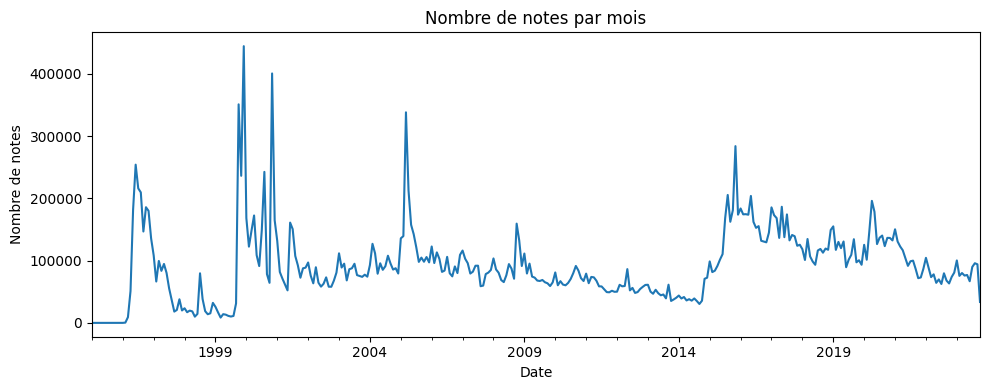

In [30]:
# Nombre de notes par mois
notes_par_mois = ratings_movies.groupby(ratings_movies["date"].dt.to_period("M")).size()

fig, ax = plt.subplots(figsize=(10, 4))
notes_par_mois.plot(ax=ax)
ax.set_title("Nombre de notes par mois")
ax.set_xlabel("Date")
ax.set_ylabel("Nombre de notes")
plt.tight_layout()
plt.show()

# IV - Analyse de l'évolution des notes des films dans le temps

### A) Comment évolue la notation des utilisateurs dans le temps ?

### B) Comment évolue la notation des films dans le temps ?

Création de la table de travail pour cette partie : 

In [31]:
# On travaille sur une copie pour ne pas modifier la table originale en ne sélectionnant que les colonnes utiles (32M de lignes donc évite de copier les colonnes inutiles)
df_anciennete = ratings_movies[
    ["movieId", "rating", "date", "year"]
].copy()

# On s'assure que les colonnes ont le bon format
df_anciennete["date"] = pd.to_datetime(df_anciennete["date"], errors="coerce")
df_anciennete["year"] = pd.to_numeric(df_anciennete["year"], errors="coerce")

# Écart entre l'année de notation et l'année de sortie (mais chiant qu'on ait pas une date de sortie plus précise ??? --> aller la récup aiileurs ? )
df_anciennete["anciennete"] = (
    df_anciennete["date"].dt.year - df_anciennete["year"]
)

# On retire les lignes sans date/année, et les notes antérieures à l'année de sortie
df_anciennete = df_anciennete.dropna(
    subset=["date", "year", "anciennete"]
)
df_anciennete = df_anciennete[df_anciennete["anciennete"] >= 0].copy()

print(f"Notes utilisées : {len(df_anciennete):,}")

Notes utilisées : 31,964,024


Ensuite, regroupe les notes en tranches d’ancienneté (tranche pas non plus trop précises pr garder du volume : quel bon compromis ?) :

In [32]:
##bornes = [-1, 0, 1, 4, 9, 19, float("inf")]
###etiquettes = ["Même année","1 an après","2–4 ans","5–9 ans","10–19 ans","20 ans et plus"]

###df_anciennete["tranche_anciennete"] = pd.cut(df_anciennete["anciennete"],bins=bornes,labels=etiquettes)


df_anciennete["tranche_anciennete"] = (
    df_anciennete["anciennete"].astype(int)
)

Plusieurs méthodes ensuite pour analyser tout ca : 

1)Pour éviter que les films très populaires pèsent beaucoup plus lourd que les autres, on calcule d’abord la moyenne des notes de chaque film dans chaque tranche, puis la moyenne entre films.

2)Ne pas éviter que les films très popus pèsent plus : en effet, c'est pê eux qui représente l'effet que l'on cherche à mettre en valeur (augmentation de la note moyenne avec le temps) --> à vérifier par ailleurs, en tracant l'évolution pour un groupe de films popu / un groupe de films moins popu .....

In [37]:
# Une ligne par film et par ancienneté
par_film = (
    df_anciennete
    .groupby(["movieId", "tranche_anciennete"], observed=True)["rating"]
    .agg(
        moyenne_film="mean",
        somme_notes="sum",
        nombre_notes="count",
    )
    .reset_index()
)

# Méthode 1 : chaque film pèse autant
resume_anciennete = (
    par_film
    .groupby("tranche_anciennete", observed=True)
    .agg(
        note_moyenne=("moyenne_film", "mean"),
        nombre_films=("movieId", "count"),
        nombre_notes=("nombre_notes", "sum"),
    )
)

# Méthode 2 : chaque note pèse autant
resume_anciennete_non_moyenne = (
    par_film
    .groupby("tranche_anciennete", observed=True)
    .agg(
        somme_notes=("somme_notes", "sum"),
        nombre_notes=("nombre_notes", "sum"),
        nombre_films=("movieId", "count"),
    )
)

resume_anciennete_non_moyenne["note_moyenne"] = (
    resume_anciennete_non_moyenne["somme_notes"]
    / resume_anciennete_non_moyenne["nombre_notes"]
)

resume_anciennete_non_moyenne = resume_anciennete_non_moyenne.drop(
    columns="somme_notes"
)

display(resume_anciennete_non_moyenne.head())

,nombre_notes,nombre_films,note_moyenne
tranche_anciennete,,,
0,1078630,14920,3.416317
1,2716651,22066,3.504673
2,2099407,22347,3.502673
3,1734329,21359,3.512325
4,1430576,20142,3.500895


Puis on affiche l'évolution de ces deux moyennes en fonction du temps ainsi que les volumes de nos cohortes dans chacune des méthodes :

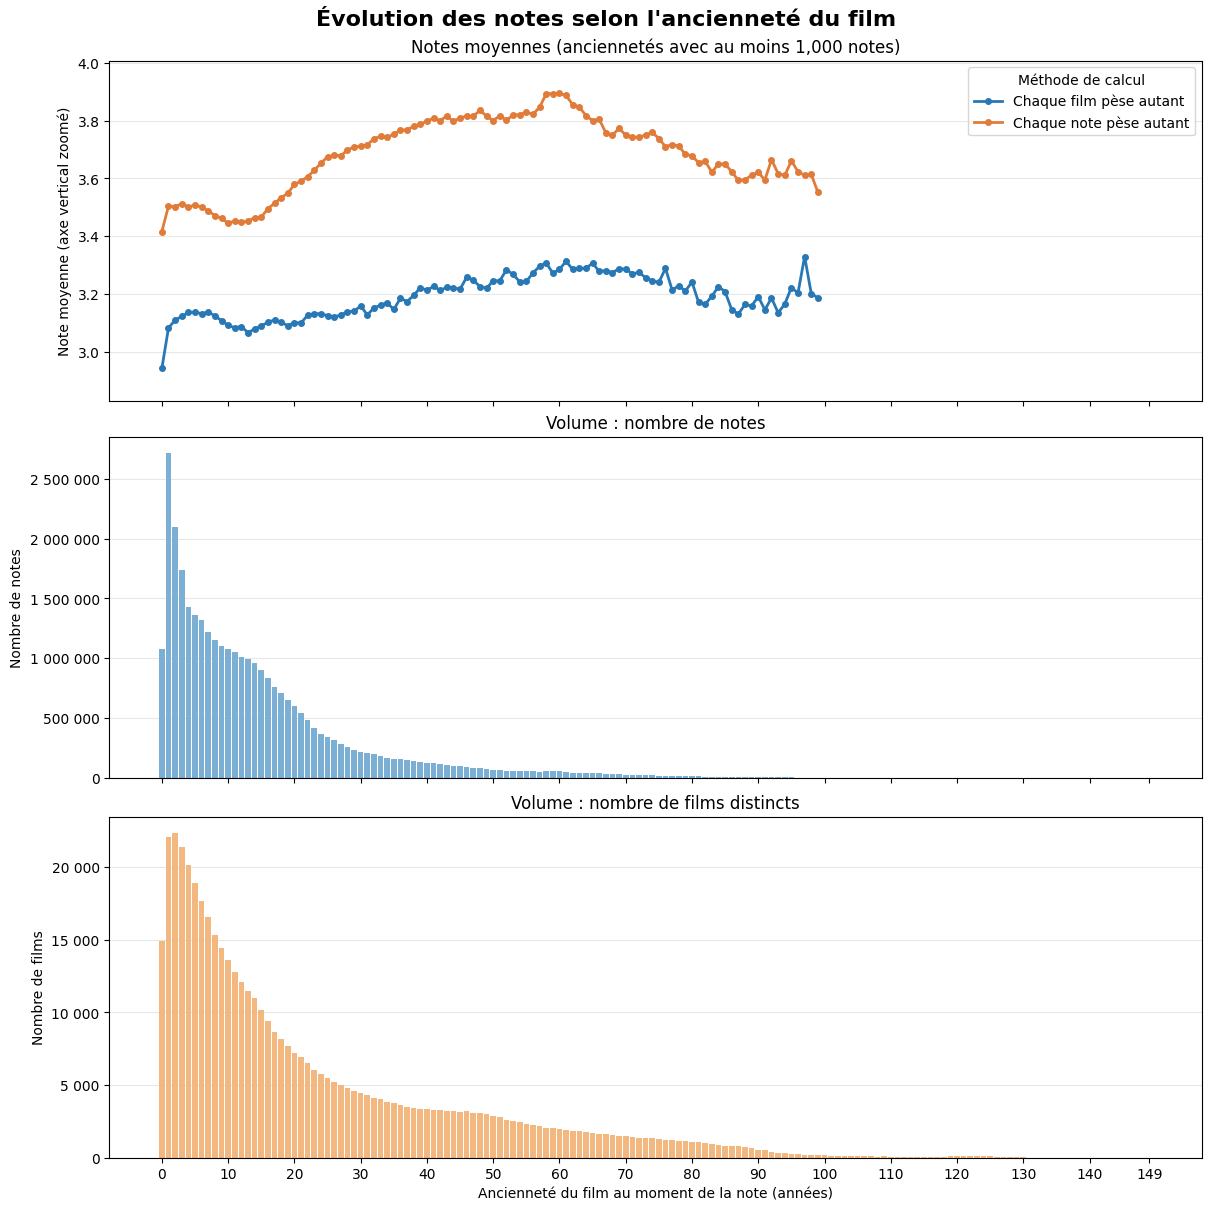

In [39]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

seuil_notes = 1000

resume_notes = resume_anciennete_non_moyenne.sort_index()
ages = resume_notes.index

nombre_notes = resume_notes["nombre_notes"]
nombre_films = resume_anciennete["nombre_films"].reindex(ages)

# Pour comparer les moyennes, on ne garde que les anciennetés
# avec au moins seuil_notes notes.
assez_de_notes = nombre_notes >= seuil_notes

moyenne_par_film = (
    resume_anciennete["note_moyenne"]
    .reindex(ages)
    .where(assez_de_notes)
)

moyenne_par_note = (
    resume_notes["note_moyenne"]
    .where(assez_de_notes)
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 12),
    sharex=True,
    constrained_layout=True,
)

fig.suptitle(
    "Évolution des notes selon l'ancienneté du film",
    fontsize=16,
    fontweight="bold",
)

# Graphique 1 : comparaison des moyennes
moyenne_par_film.plot(
    ax=axes[0],
    color="#2878B5",
    marker="o",
    markersize=4,
    linewidth=2,
    label="Chaque film pèse autant",
)

moyenne_par_note.plot(
    ax=axes[0],
    color="#E07B39",
    marker="o",
    markersize=4,
    linewidth=2,
    label="Chaque note pèse autant",
)

axes[0].set_title(
    f"Notes moyennes (anciennetés avec au moins {seuil_notes:,} notes)"
)
axes[0].set_ylabel("Note moyenne")
valeurs = pd.concat([moyenne_par_film, moyenne_par_note]).dropna()
marge = max((valeurs.max() - valeurs.min()) * 0.12, 0.05)

axes[0].set_ylim(
    max(0.5, valeurs.min() - marge),
    min(5, valeurs.max() + marge),
)
axes[0].set_ylabel("Note moyenne (axe vertical zoomé)")
axes[0].legend(title="Méthode de calcul", frameon=True)
axes[0].grid(axis="y", alpha=0.3)

# Graphique 2 : nombre de notes
axes[1].bar(ages, nombre_notes, color="#7BAFD4", width=0.85)
axes[1].set_title("Volume : nombre de notes")
axes[1].set_ylabel("Nombre de notes")
axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda valeur, _: f"{valeur:,.0f}".replace(",", " "))
)
axes[1].grid(axis="y", alpha=0.3)
axes[1].set_axisbelow(True)

# Graphique 3 : nombre de films distincts
axes[2].bar(ages, nombre_films, color="#F2B880", width=0.85)
axes[2].set_title("Volume : nombre de films distincts")
axes[2].set_ylabel("Nombre de films")
axes[2].set_xlabel("Ancienneté du film au moment de la note (années)")
axes[2].yaxis.set_major_formatter(
    FuncFormatter(lambda valeur, _: f"{valeur:,.0f}".replace(",", " "))
)
axes[2].grid(axis="y", alpha=0.3)
axes[2].set_axisbelow(True)

age_max = int(ages.max())
graduations = list(range(0, age_max + 1, 10))
if graduations[-1] != age_max:
    graduations.append(age_max)

axes[2].set_xticks(graduations)

plt.show()

Intéressant: note moyenne augmente avec l'ancienneté jusqu'à 60 ans puis dégringuole ..... questionnement sur la significativité de cette analyse ... mais après aussi films qu'on regarde encore longtemps après leur sortie sont les "classiques" : un pool de films un peu particuliers .... 
cumul de 2 effets : effet de notation + effet de classique : les distinguer ?
question aussi sur le nombre de films différents notés à 70 ans d'ancienneté : il peut encore rester des notes mais de 4 films très notés mais très classiques..... 
